# 02 · Diffusion vs flow matching on colour images

Same comparison as in `01_toy_2d.ipynb`, now on ~1000 colour images of butterflies from Hugging Face (`huggan/smithsonian_butterflies_subset`). The network is a U-Net from Hugging Face `diffusers`
(`UNet2DModel`). The training objectives and samplers are our own (`src/dfm`).

**Runtime.** Should work for the free GPU offered by Colab. Around 1.5 hours for training each model. If a trained model is found in `checkpoints/` it is loaded instead of retrained, so the
sampling sections can be re-run in a couple of minutes.

In [1]:
# On Colab: install the project from GitHub
import importlib.util, os, subprocess, sys
if "google.colab" in sys.modules and importlib.util.find_spec("dfm") is None:
    # Colab's preinstalled torchao is older than what recent diffusers expects so we upgrade it
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "torchao",
                    "git+https://github.com/PolTibau/diffusion-vs-flow-matching"], check=True)
    print("Installed. Restarting the session: when it reconnects, run all cells again.")
    os.kill(os.getpid(), 9)

In [2]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from dfm import Diffusion, FlowMatching, make_unet, train
from dfm.data import loader_butterflies
from dfm import viz

device = "cuda" if torch.cuda.is_available() else "cpu"
IMAGE_SIZE, STEPS, BATCH = 64, 8000, 64
try:  #keep checkpoints and GIFs in Google Drive so they survive a disconnect
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/diffusion-vs-flow-matching")
    CKPT, ASSETS = DRIVE / "checkpoints", DRIVE / "assets"
except ImportError:
    CKPT = Path("checkpoints")
    ASSETS = Path("../assets") if Path("../assets").exists() else Path("assets")
CKPT.mkdir(parents=True, exist_ok=True); ASSETS.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0)
print(device, IMAGE_SIZE, STEPS)

cuda 64 8000


## 1. Data

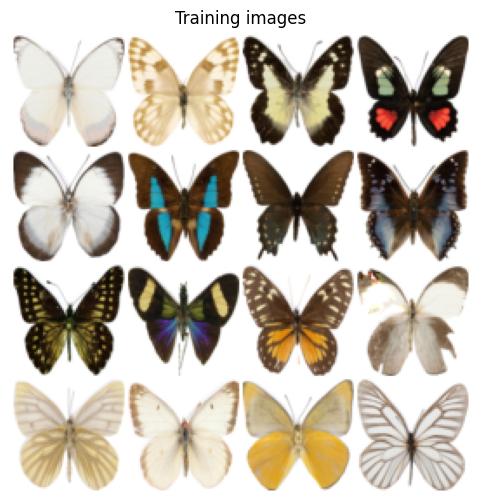

In [3]:
loader = loader_butterflies(image_size=IMAGE_SIZE, batch_size=BATCH)
(batch,) = next(iter(loader))
plt.figure(figsize=(6, 6)); viz.show_grid(batch[:16], "Training images"); plt.show()

## 2. Training

Two identical U-Nets (~15M parameters), trained with the same optimiser, learning-rate
schedule and number of steps. We keep an exponential moving average (EMA) of the weights,
standard practice for diffusion models.

In [4]:
methods = {"Diffusion": Diffusion(num_steps=1000, schedule="cosine"), "FM": FlowMatching()}
models, losses = {}, {}
for name, method in methods.items():
    path = CKPT / f"{name.lower()}_{IMAGE_SIZE}.pt"
    model = make_unet(IMAGE_SIZE)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=device)); models[name] = model.to(device).eval()
        print(f"{name}: loaded {path}")
        continue
    t0 = time.time()
    models[name], losses[name] = train(model, method, loader, steps=STEPS, lr=2e-4, device=device, ema_decay=0.999)
    torch.save(models[name].state_dict(), path)
    print(f"{name}: {(time.time() - t0) / 60:.1f} min")

Diffusion: 95.2 min


FM: 95.3 min


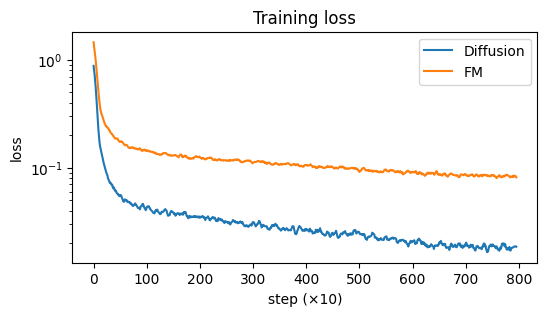

In [5]:
if losses:
    fig, ax = plt.subplots(figsize=(6, 3))
    for name, l in losses.items():
        ax.plot(torch.tensor(l).unfold(0, 50, 10).mean(1), label=name)
    ax.set(yscale="log", xlabel="step (×10)", ylabel="loss", title="Training loss"); ax.legend(); plt.show()

As comented in the first notebook, both losses are not comparable. Diffusion regresses the noise ε, which is nearly
the input itself at high noise, while flow matching regresses the velocity x₁ − x₀, which
always has to be inferred. Only the samples tell which model is better.

## 3. Samples

Diffusion with its two samplers (stochastic DDPM, 1000 steps; deterministic DDIM, 50
steps) and flow matching with 50 Euler steps.

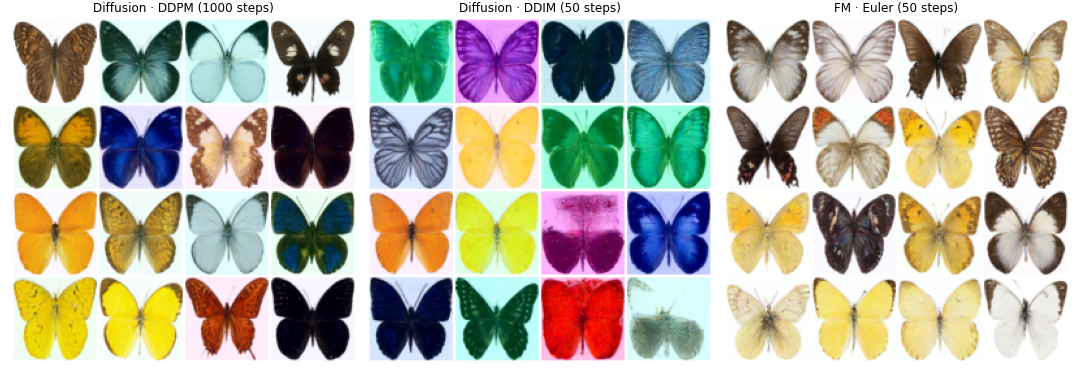

In [6]:
n = 16
shape = (n, 3, IMAGE_SIZE, IMAGE_SIZE)
torch.manual_seed(1)
D, FM = methods["Diffusion"], methods["FM"]
samples = {
    "Diffusion · DDPM (1000 steps)": D.sample_ddpm(models["Diffusion"], shape, device=device, clip=1.0),
    "Diffusion · DDIM (50 steps)": D.sample_ddim(models["Diffusion"], shape, steps=50, device=device, clip=1.0),
    "FM · Euler (50 steps)": FM.sample(models["FM"], shape, steps=50, device=device),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.3))
for ax, (name, x) in zip(axes, samples.items()):
    viz.show_grid(x, name, ax)
plt.tight_layout(); plt.show()

**What we see.** Flow matching produces butterflies with natural colours on white
backgrounds, like the training images. DDPM, from the diffusion network, is close (slightly
tinted backgrounds). DDIM, from **the same network**, drifts strongly: coloured backgrounds,
over-saturated single-colour wings.

A plausible explanation. With ε-prediction the clean image is only recovered through
x̂₀ = (x_t − √(1−ᾱ_t) ε̂) / √ᾱ_t, which multiplies the network error by 1/√ᾱ_t (≈ 30 at
t = 0.98): the global colour, decided in those first very noisy steps, is poorly controlled.
DDIM follows the probability-flow ODE deterministically, so an early error is carried to the
end; DDPM injects fresh noise at every step, which lets later steps correct earlier mistakes
(Karras et al., 2022, make the same observation). Flow matching is deterministic too, but its
target, the velocity x₁ − x₀, contains the data at every time, so it is never ill-conditioned
near the noise; *v-prediction* (Salimans & Ho, 2022) was introduced for diffusion for the same
reason.

With the cosine schedule the first reverse DDPM step has α ≈ 0.001,
and the plain update divides by √α ≈ 0.03: without clipping x̂₀ to [−1, 1] the samples blow
up into flat colours (`sample_ddpm(..., clip=1.0)`).

## 4. Few-step generation

Starting from **the same noise**, we generate with 1, 2, 5, 10 and 50 steps. The
deterministic samplers (DDIM and FM) map each noise to one image, so we can compare them
directly.

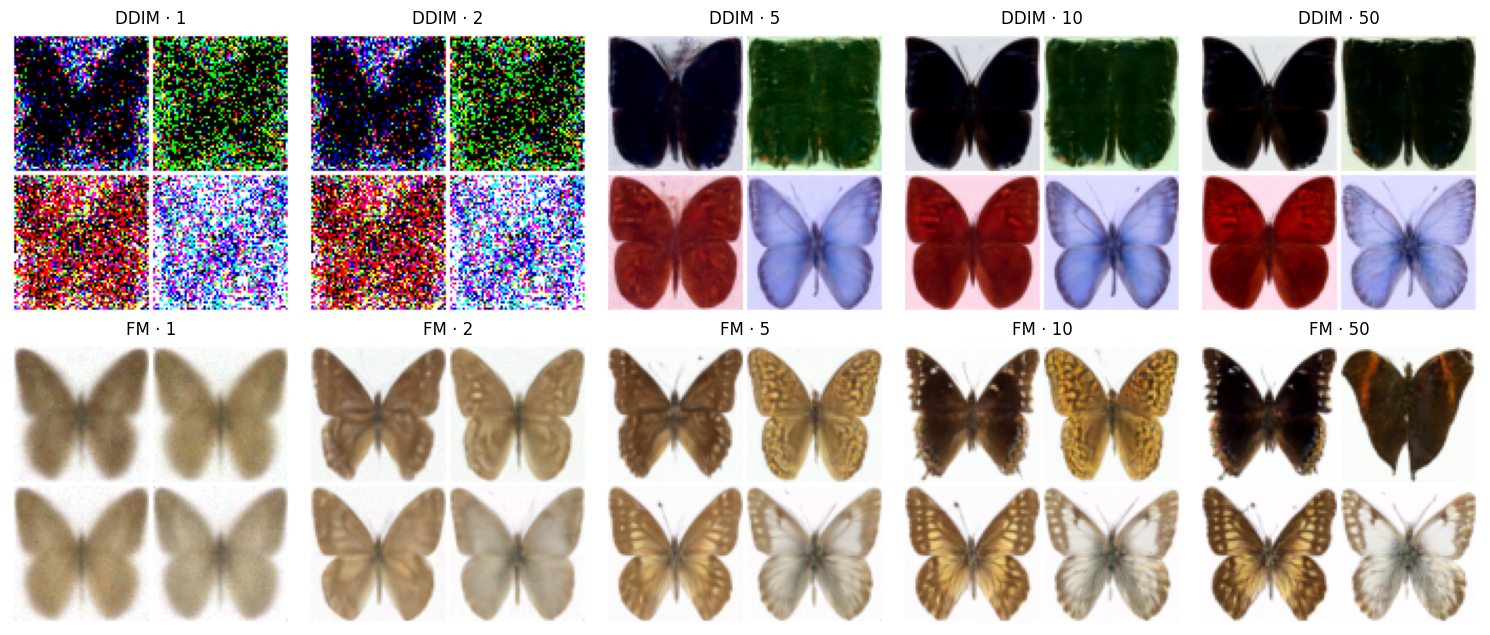

In [7]:
torch.manual_seed(2)
noise = torch.randn(4, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
step_grid = [1, 2, 5, 10, 50]
fig, axes = plt.subplots(2, len(step_grid), figsize=(3 * len(step_grid), 6.5))
for c, s in enumerate(step_grid):
    torch.manual_seed(2)  # DDIM draws its own noise: reseed to get the same one
    viz.show_grid(D.sample_ddim(models["Diffusion"], noise.shape, steps=s, device=device, clip=1.0), f"DDIM · {s}", axes[0, c])
    viz.show_grid(FM.sample(models["FM"], noise.shape, steps=s, device=device, x0=noise), f"FM · {s}", axes[1, c])
plt.tight_layout(); plt.show()

**What we see.** With 1-2 steps DDIM has to jump from pure noise (ᾱ ≈ 2·10⁻⁹) to an
image, and x̂₀ amplifies the network error by ~10⁴: clipped, it is just saturated noise. Flow
matching with **one** Euler step already gives a butterfly, blurry because it is the average
of all butterflies compatible with that noise (E[x₁ | x₀]); with 2-5 steps the details appear,
and 10 steps are hardly distinguishable from 50. The straighter paths of flow matching pay
off exactly in this few-step regime, as in the 2D experiment.

## 5. Watching the generation (GIFs)

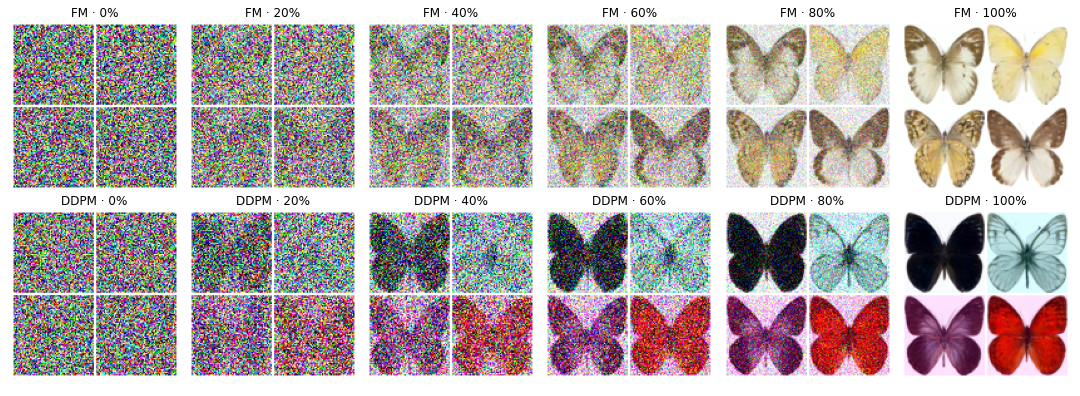

GIFs saved to assets


In [8]:
torch.manual_seed(3)
_, traj_fm = FM.sample(models["FM"], (16, 3, IMAGE_SIZE, IMAGE_SIZE), steps=50, device=device, keep=50)
_, traj_ddpm = D.sample_ddpm(models["Diffusion"], (16, 3, IMAGE_SIZE, IMAGE_SIZE), device=device, keep=50, clip=1.0)
viz.save_gif(traj_fm, ASSETS / "flow_matching.gif")
viz.save_gif(traj_ddpm, ASSETS / "ddpm.gif")

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for row, (name, traj) in enumerate([("FM", traj_fm), ("DDPM", traj_ddpm)]):
    for c, i in enumerate([0, 10, 20, 30, 40, 50]):
        viz.show_grid(traj[i][:4], f"{name} · {i / 50:.0%}", axes[row, c])
plt.tight_layout(); plt.show()
print("GIFs saved to", ASSETS)

## 6. Interpolating in noise space

Flow matching is a deterministic map from noise to images. Moving smoothly between two
noise vectors (spherical interpolation) gives a smooth morph between two butterflies.

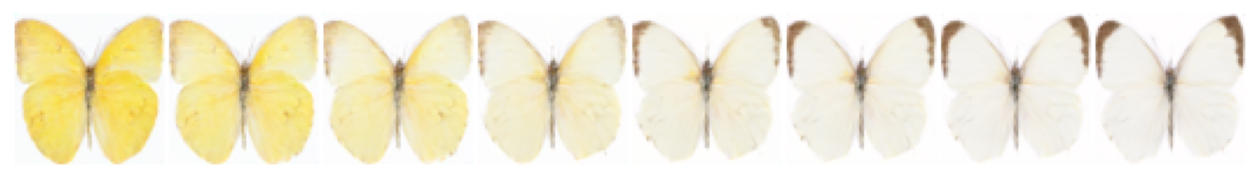

In [9]:
def slerp(a, b, w):
    omega = torch.acos(((a / a.norm()) * (b / b.norm())).sum().clamp(-1, 1))
    return (torch.sin((1 - w) * omega) * a + torch.sin(w * omega) * b) / torch.sin(omega)

torch.manual_seed(4)
a, b = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
ws = torch.linspace(0, 1, 8)
z = torch.stack([slerp(a, b, w) for w in ws])
x = FM.sample(models["FM"], z.shape, steps=50, device=device, x0=z)
plt.figure(figsize=(16, 2.5)); plt.imshow(viz.to_image(x, nrow=len(ws))); plt.axis("off"); plt.show()

## Takeaways

- **Same U-Net, same budget** (8000 steps, 95 min each on a T4): flow matching with 50 steps
  reproduces the colours of the data; diffusion needs the 1000 stochastic DDPM steps to get
  close, and drifts in colour with deterministic DDIM.
- **Few steps:** flow matching is recognisable with 2 steps and nearly converged at 5-10;
  DDIM needs at least 5 and fails completely at 1-2.
- **Stability:** with the cosine schedule, DDPM sampling needs x̂₀ clipping.
- **Natural next experiment:** train the diffusion model with v-prediction, to see whether
  DDIM's colour drift disappears, i.e. whether the parametrisation rather than the noising
  process explains the gap.